## MDP

In [145]:
import numpy as np
import matplotlib.pyplot as plt

# Grid World Enviroment
# 0 = Free, 1 = Objective, 2 = Hole, 3 = Obstacle
world = np.array([[0, 0, 0, 0, 2], 
                  [0, 3, 3, 0, 0],
                  [0, 3, 0, 0, 2],
                  [0, 0, 0, 0, 0],
                  [0, 3, 2, 1, 0],])

# world = mini_world = np.array([[0,0],[2,1]])

# explotation and exploration
# finite and infinite horizon
time_step = 0 # D

In [135]:
def states(world) -> dict:
    set_of_states = {}
    labels = {0: "Free", 
              1: "Objective", 
              2: "Hole", 
              3: "Obstacle"}
    
    for row in range(world.shape[0]):
        for col in range(world.shape[1]):
            state = (row, col)
            set_of_states[state] = labels[world[row, col]]

    return set_of_states


def actions() -> dict:
    set_of_actions = {"LEFT": (0, -1),
                      "RIGHT": (0, 1), 
                      "DOWN": (1, 0), 
                      "UP": (-1, 0)}
    
    return set_of_actions


def transitions(set_of_states, set_of_actions, deterministic=True, slip_prob=0.2) -> dict:
    set_of_transitions = {}
    perpendiculares = {"LEFT":  ["UP", "DOWN"], 
                       "RIGHT": ["UP", "DOWN"],
                       "UP":    ["LEFT", "RIGHT"], 
                       "DOWN":  ["LEFT", "RIGHT"],}

    def next_state(s1, movement):
        s2 = tuple(int(x) for x in np.array(s1) + np.array(movement))
        is_valid = (0 <= s2[0] < world.shape[0] and 0 <= s2[1] < world.shape[1] and set_of_states[s2] != "Obstacle")
        return s2 if is_valid else s1

    for s1 in set_of_states:
        set_of_transitions[s1] = {}

        for action, movement in set_of_actions.items():
            dist = {}

            if deterministic:
                moves = [(movement, 1.0)]

            else:
                others = perpendiculares[action]
                moves = [(movement, 1 - slip_prob)]
                for other_action in others:
                    moves.append((set_of_actions[other_action], slip_prob / len(others)))

            for mv, prob in moves:
                destino = next_state(s1, mv)
                dist[destino] = dist.get(destino, 0.0) + prob

            set_of_transitions[s1][action] = dist

    return set_of_transitions


def rewards(world) -> dict:
    set_of_rewards = {}
    reward_values = {0: -1,   # Free
                     1: 10,   # Objective
                     2: -10,  # Hole
                     3: 0}    # Obstacle

    for row in range(world.shape[0]):
        for col in range(world.shape[1]):
            state = (row, col)
            set_of_rewards[state] = reward_values[world[row, col]]

    return set_of_rewards


set_of_states = states(world)
set_of_actions = actions()
set_of_transitions = transitions(set_of_states, set_of_actions, deterministic=True, slip_prob=0.4)
set_of_rewards = rewards(world)

print(f"States {set_of_states}\n",
      f"\nActions {set_of_actions}\n",
      f"\nTransitions {set_of_transitions}\n",
      f"\nRewards {set_of_rewards}")

States {(0, 0): 'Free', (0, 1): 'Free', (0, 2): 'Free', (0, 3): 'Free', (0, 4): 'Hole', (1, 0): 'Free', (1, 1): 'Obstacle', (1, 2): 'Obstacle', (1, 3): 'Free', (1, 4): 'Free', (2, 0): 'Free', (2, 1): 'Obstacle', (2, 2): 'Free', (2, 3): 'Free', (2, 4): 'Hole', (3, 0): 'Free', (3, 1): 'Free', (3, 2): 'Free', (3, 3): 'Free', (3, 4): 'Free', (4, 0): 'Free', (4, 1): 'Obstacle', (4, 2): 'Hole', (4, 3): 'Objective', (4, 4): 'Free'}
 
Actions {'LEFT': (0, -1), 'RIGHT': (0, 1), 'DOWN': (1, 0), 'UP': (-1, 0)}
 
Transitions {(0, 0): {'LEFT': {(0, 0): 1.0}, 'RIGHT': {(0, 1): 1.0}, 'DOWN': {(1, 0): 1.0}, 'UP': {(0, 0): 1.0}}, (0, 1): {'LEFT': {(0, 0): 1.0}, 'RIGHT': {(0, 2): 1.0}, 'DOWN': {(0, 1): 1.0}, 'UP': {(0, 1): 1.0}}, (0, 2): {'LEFT': {(0, 1): 1.0}, 'RIGHT': {(0, 3): 1.0}, 'DOWN': {(0, 2): 1.0}, 'UP': {(0, 2): 1.0}}, (0, 3): {'LEFT': {(0, 2): 1.0}, 'RIGHT': {(0, 4): 1.0}, 'DOWN': {(1, 3): 1.0}, 'UP': {(0, 3): 1.0}}, (0, 4): {'LEFT': {(0, 3): 1.0}, 'RIGHT': {(0, 4): 1.0}, 'DOWN': {(1, 4): 1.0

## Value Iteration

In [136]:
def value_iteration(mdp, theta=1e-4):
    S, A, T, R, gamma = mdp["S"], mdp["A"], mdp["T"], mdp["R"], mdp["gamma"]
    terminais = {"Objective", "Hole", "Obstacle"}
    deltas = []

    V = {}
    for s in S:
        V[s] = 0.0

    while True:
        delta = 0.0
        V_ = V.copy()

        for s in S:
            if S[s] in terminais:
                V_[s] = 0.0
                continue

            action_values = []
            for a in A:
                total = sum(prob * (R[s2] + gamma * V[s2]) for s2, prob in T[s][a].items())
                action_values.append(total)

            V_[s] = max(action_values)
            delta = max(delta, abs(V_[s] - V[s]))

        V = V_
        deltas.append(delta)

        if delta <= theta:
            break

    return V, deltas


def policy_extraction(mdp, V):
    S, A, T, R, gamma = mdp["S"], mdp["A"], mdp["T"], mdp["R"], mdp["gamma"]
    terminais = {"Objective", "Hole", "Obstacle"}
    policy = {}

    for s in S:
        if S[s] in terminais:
            policy[s] = None
            continue

        best_action, best_value = None, -float("inf")
        for a in A:
            total = sum(prob * (R[s2] + gamma * V[s2]) for s2, prob in T[s][a].items())

            if total > best_value:
                best_value, best_action = total, a

        policy[s] = best_action

    return policy


mdp = {"S": states(world),
       "A": actions(),
       "T": transitions(set_of_states, set_of_actions, deterministic=False),
       "R": rewards(world),
       "gamma": 0.9}

V, deltas = value_iteration(mdp)
policy = policy_extraction(mdp, V)

print("V:", V)
print("Number of iterations to converge", len(deltas))
print("Policy:", policy)

V: {(0, 0): -2.4852356704696863, (0, 1): -2.4167087949794386, (0, 2): -1.3634691711601554, (0, 3): -0.16394939003994816, (0, 4): 0.0, (1, 0): -1.4500486820846805, (1, 1): 0.0, (1, 2): 0.0, (1, 3): 2.581615605870934, (1, 4): -0.9412369161555432, (2, 0): -0.2625371196010262, (2, 1): 0.0, (2, 2): 3.1464057799210745, (2, 3): 4.769418899762754, (2, 4): 0.0, (3, 0): 1.0898956919691416, (3, 1): 2.968270179089747, (3, 2): 4.769418899762754, (3, 3): 8.869781111551434, (3, 4): 7.1170379516725175, (4, 0): -0.2625371196010262, (4, 1): 0.0, (4, 2): 0.0, (4, 3): 0.0, (4, 4): 9.275311444534161}
Number of iterations to converge 23
Policy: {(0, 0): 'DOWN', (0, 1): 'RIGHT', (0, 2): 'RIGHT', (0, 3): 'DOWN', (0, 4): None, (1, 0): 'DOWN', (1, 1): None, (1, 2): None, (1, 3): 'DOWN', (1, 4): 'LEFT', (2, 0): 'DOWN', (2, 1): None, (2, 2): 'RIGHT', (2, 3): 'DOWN', (2, 4): None, (3, 0): 'RIGHT', (3, 1): 'RIGHT', (3, 2): 'RIGHT', (3, 3): 'DOWN', (3, 4): 'DOWN', (4, 0): 'UP', (4, 1): None, (4, 2): None, (4, 3): No

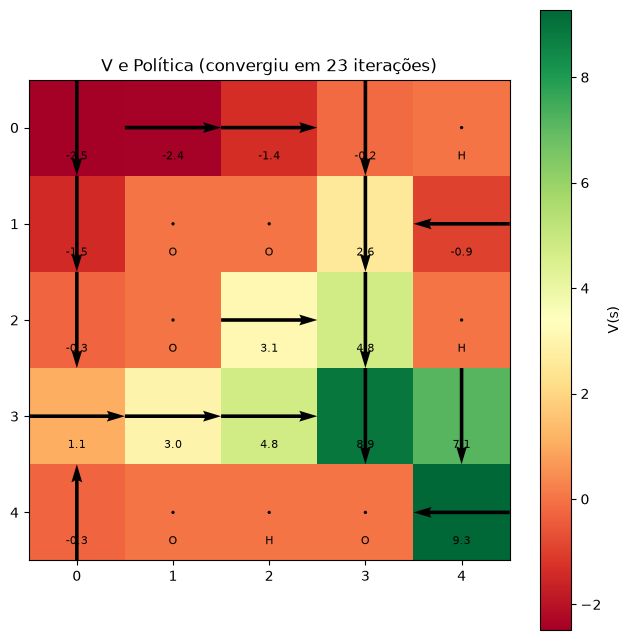

In [ ]:
def v_to_matrix(V, world):
    matriz = np.zeros(world.shape)
    for (r, c), valor in V.items():
        matriz[r, c] = valor
    return matriz


def politica_to_setas(politica, world):
    seta_por_acao = {"LEFT": (-1, 0), "RIGHT": (1, 0), "UP": (0, 1), "DOWN": (0, -1)}
    U = np.zeros(world.shape)
    Vv = np.zeros(world.shape)
    for (r, c), acao in politica.items():
        if acao is None:
            continue
        dx, dy = seta_por_acao[acao]
        U[r, c] = dx
        Vv[r, c] = dy
    return U, Vv


def plot_value_and_policy(V, politica, world, set_of_states, plot_size=1.3,titulo="Value Iteration"):
    matriz_V = v_to_matrix(V, world)
    U, Vv = politica_to_setas(politica, world)

    fig, ax = plt.subplots(figsize=(world.shape[1] * plot_size, world.shape[0] * plot_size))
    im = ax.imshow(matriz_V, cmap="RdYlGn")
    fig.colorbar(im, ax=ax, label="V(s)")

    rows, cols = np.meshgrid(np.arange(world.shape[0]), np.arange(world.shape[1]), indexing="ij")
    ax.quiver(cols, rows, U, Vv, color="black", scale=1, scale_units="xy", pivot="mid")

    for (r, c), label in set_of_states.items():
        texto = f"{matriz_V[r, c]:.1f}"
        if label in ("Objective", "Hole", "Obstacle"):
            texto = label[0]
        ax.text(c, r + 0.3, texto, ha="center", va="center", fontsize=8, color="black")

    ax.set_xticks(range(world.shape[1]))
    ax.set_yticks(range(world.shape[0]))
    ax.set_title(titulo)
    plt.tight_layout()
    return fig


fig = plot_value_and_policy(V, policy, world, set_of_states, plot_size=1.3,
                            titulo=f"V e Política (convergiu em {len(deltas)} iterações)")
plt.show()

# q-learning
# V = {s: max(Q[(s, a)] for a in set_of_actions) for s in set_of_states}
# policy = {s: max(set_of_actions, key=lambda a: Q[(s, a)]) for s in set_of_states}